In [1]:
import re
import json
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from datasets import load_dataset
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

print("TensorFlow:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
dataset = load_dataset(
    "Salesforce/wikitext",
    "wikitext-2-raw-v1"
)

print(dataset)
print(dataset["train"][0])

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

...

wikitext-2-raw-v1/validation-00000-of-00(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

DatasetDict({
    test: Dataset({
        features: ['text'],
        num_rows: 4358
    })
    train: Dataset({
        features: ['text'],
        num_rows: 36718
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 3760
    })
})
{'text': ''}


In [3]:
for split in ["train", "validation", "test"]:
    print(f"\n{split.upper()}")
    print("Number of rows:", len(dataset[split]))
    print("Sample:", repr(dataset[split][0]["text"][:300]))


TRAIN
Number of rows: 36718
Sample: ''

VALIDATION
Number of rows: 3760
Sample: ''

TEST
Number of rows: 4358
Sample: ''


In [4]:
def prepare_text(split):
    lines = [
        row["text"].strip()
        for row in dataset[split]
        if row["text"].strip()
    ]

    # Treat each non-empty row as a separate text segment.
    return "\n".join(lines)


train_text = prepare_text("train")
val_text = prepare_text("validation")
test_text = prepare_text("test")

print("Training characters:", len(train_text))
print("Validation characters:", len(val_text))
print("Test characters:", len(test_text))

print("\nSample training text:\n")
print(train_text[:1000])

Training characters: 10845452
Validation characters: 1137224
Test characters: 1279839

Sample training text:

= Valkyria Chronicles III =
Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role @-@ playing video game developed by Sega and Media.Vision for the PlayStation Portable . Released in January 2011 in Japan , it is the third game in the Valkyria series . Employing the same fusion of tactical and real @-@ time gameplay as its predecessors , the story runs parallel to the first game and follows the " Nameless " , a penal military unit serving the nation of Gallia during the Second Europan War who perform secret black operations and are pitted against the Imperial unit " Calamaty Raven " .
The game began development in 2010 , carrying over a large portion of the work done on Valkyria Chronicles II . While it retained the standard features of the

In [5]:
MAX_VOCAB_SIZE = 20000
OOV_TOKEN = "<OOV>"

tokenizer = Tokenizer(
    num_words=MAX_VOCAB_SIZE,
    oov_token=OOV_TOKEN,
    filters="",          # Preserve punctuation as tokens
    lower=False
)

tokenizer.fit_on_texts([train_text])

vocab_size = min(
    MAX_VOCAB_SIZE,
    len(tokenizer.word_index) + 1
)

print("Vocabulary size:", vocab_size)
print("Sample word IDs:", list(tokenizer.word_index.items())[:20])

Vocabulary size: 20000
Sample word IDs: [('<OOV>', 1), ('the', 2), (',', 3), ('.', 4), ('of', 5), ('and', 6), ('in', 7), ('to', 8), ('a', 9), ('"', 10), ('was', 11), ('=', 12), ('@-@', 13), ('The', 14), ('that', 15), ('as', 16), ("'s", 17), ('on', 18), ('for', 19), ('with', 20)]


In [6]:
train_ids = tokenizer.texts_to_sequences([train_text])[0]
val_ids = tokenizer.texts_to_sequences([val_text])[0]
test_ids = tokenizer.texts_to_sequences([test_text])[0]

print("Training tokens:", len(train_ids))
print("Validation tokens:", len(val_ids))
print("Test tokens:", len(test_ids))

Training tokens: 2028144
Validation tokens: 211426
Test tokens: 238321


In [7]:
SEQ_LENGTH = 10

def make_examples(split, tokenizer, seq_length):
    X_parts = []
    y_parts = []

    for row in dataset[split]:
        text = row["text"].strip()

        if not text:
            continue

        ids = tokenizer.texts_to_sequences([text])[0]

        if len(ids) <= seq_length:
            continue

        # Sliding windows: 10 input tokens predict token 11.
        ids = np.asarray(ids, dtype=np.int32)

        windows = np.lib.stride_tricks.sliding_window_view(
            ids, seq_length + 1
        )

        X_parts.append(windows[:, :-1])
        y_parts.append(windows[:, -1])

    if not X_parts:
        raise ValueError("No sequences created. Check the dataset and sequence length.")

    return np.concatenate(X_parts), np.concatenate(y_parts)


X_train, y_train = make_examples(
    "train", tokenizer, SEQ_LENGTH
)

X_val, y_val = make_examples(
    "validation", tokenizer, SEQ_LENGTH
)

X_test, y_test = make_examples(
    "test", tokenizer, SEQ_LENGTH
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (1839506, 10)
y_train: (1839506,)
X_val: (191630, 10)
X_test: (215706, 10)


In [8]:
word_by_id = {
    index: word
    for word, index in tokenizer.word_index.items()
    if index < vocab_size
}

def decode_ids(ids):
    return " ".join(word_by_id.get(int(i), OOV_TOKEN) for i in ids)

print("Input:", decode_ids(X_train[0]))
print("Target:", word_by_id.get(int(y_train[0]), OOV_TOKEN))

Input: <OOV> no Valkyria 3 : <OOV> Chronicles ( Japanese :
Target: <OOV>


In [11]:
EMBEDDING_DIM = 128
LSTM_UNITS = 128

model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=EMBEDDING_DIM,
        mask_zero=False
    ),

    LSTM(LSTM_UNITS),

    Dropout(0.2),

    Dense(vocab_size, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["sparse_categorical_accuracy"]
)

model.build(input_shape=(None, SEQ_LENGTH))
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 10, 128)        │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20000)          │     2,580,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,271,584 (20.11 MB)

 Trainable params: 5,271,584 (20.11 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        "/content/best_next_word_lstm.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=128,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/20
14372/14372 ━━━━━━━━━━━━━━━━━━━━ 183s 13ms/step - loss: 5.9212 - sparse_categorical_accuracy: 0.1695 - val_loss: 5.3007 - val_sparse_categorical_accuracy: 0.2123
Epoch 2/20
14372/14372 ━━━━━━━━━━━━━━━━━━━━ 182s 13ms/step - loss: 5.2745 - sparse_categorical_accuracy: 0.2118 - val_loss: 5.0878 - val_sparse_categorical_accuracy: 0.2250
Epoch 3/20
14372/14372 ━━━━━━━━━━━━━━━━━━━━ 181s 13ms/step - loss: 5.0223 - sparse_categorical_accuracy: 0.2272 - val_loss: 5.0006 - val_sparse_categorical_accuracy: 0.2308
Epoch 4/20
14372/14372 ━━━━━━━━━━━━━━━━━━━━ 182s 13ms/step - loss: 4.8646 - sparse_categorical_accuracy: 0.2373 - val_loss: 4.9637 - val_sparse_categorical_accuracy: 0.2330
Epoch 5/20
14372/14372 ━━━━━━━━━━━━━━━━━━━━ 202s 13ms/step - loss: 4.7482 - sparse_categorical_accuracy: 0.2444 - val_loss: 4.9464 - val_sparse_categorical_accuracy: 0.2349
Epoch 6/20
14372/14372 ━━━━━━━━━━━━━━━━━━━━ 187s 13ms/step - loss: 4.6568 - sparse_categorical_accuracy: 0.2511 - val_loss: 4.9454 - va

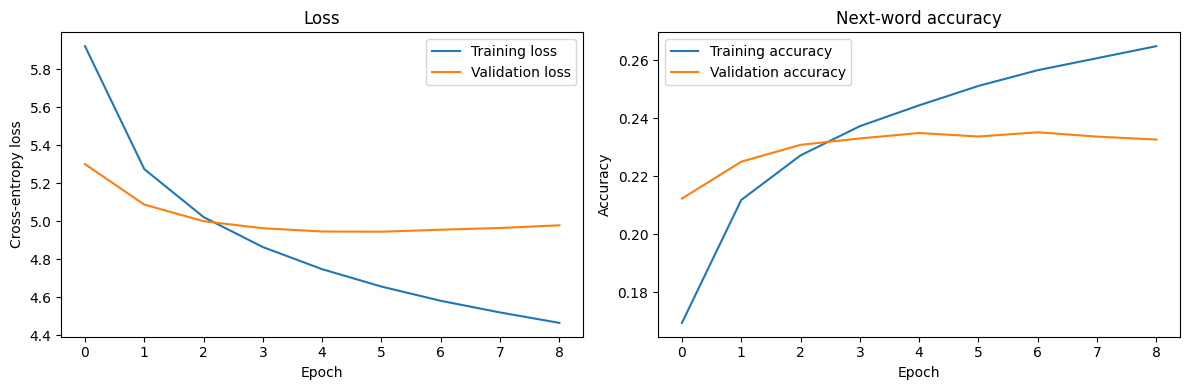

In [13]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.legend()
plt.title("Loss")

plt.subplot(1, 2, 2)
plt.plot(
    history.history["sparse_categorical_accuracy"],
    label="Training accuracy"
)
plt.plot(
    history.history["val_sparse_categorical_accuracy"],
    label="Validation accuracy"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Next-word accuracy")

plt.tight_layout()
plt.show()

In [14]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    batch_size=128,
    verbose=1
)

print(f"Test loss: {test_loss:.4f}")
print(f"Test top-1 accuracy: {test_accuracy:.4f}")
print(f"Test perplexity: {np.exp(min(test_loss, 80)):.4f}")

1686/1686 ━━━━━━━━━━━━━━━━━━━━ 15s 9ms/step - loss: 4.8975 - sparse_categorical_accuracy: 0.2351
Test loss: 4.8975
Test top-1 accuracy: 0.2351
Test perplexity: 133.9581


In [15]:
def predict_next_word(text, top_k=5):
    ids = tokenizer.texts_to_sequences([text])[0]

    if not ids:
        raise ValueError("Enter at least one recognized or tokenizable word.")

    # Keep the most recent context tokens.
    ids = ids[-SEQ_LENGTH:]

    # Left-pad shorter contexts.
    padded = pad_sequences(
        [ids],
        maxlen=SEQ_LENGTH,
        padding="pre",
        truncating="pre"
    )

    probabilities = model.predict(padded, verbose=0)[0]

    # Exclude the OOV token from suggested words.
    probabilities[tokenizer.word_index[OOV_TOKEN]] = 0

    top_ids = np.argsort(probabilities)[-top_k:][::-1]

    return [
        (
            word_by_id.get(int(idx), OOV_TOKEN),
            float(probabilities[idx])
        )
        for idx in top_ids
    ]


print(predict_next_word("The history of the"))

[('song', 0.029444679617881775), ('United', 0.0213908888399601), ('film', 0.014045742340385914), ('album', 0.011731908656656742), ('National', 0.01069497037678957)]


In [16]:
user_text = "Machine learning is"
predictions = predict_next_word(user_text)

print("Input:", user_text)
print("\nPredictions:")

for word, probability in predictions:
    print(f"{word:20s} {probability:.4f}")

Input: Machine learning is

Predictions:
also                 0.0573
a                    0.0395
not                  0.0202
used                 0.0177
often                0.0175


In [17]:
model.save("/content/next_word_lstm.keras")

with open("/content/tokenizer.json", "w", encoding="utf-8") as f:
    f.write(tokenizer.to_json())

print("Model and tokenizer saved.")

Model and tokenizer saved.


In [18]:
from google.colab import files

files.download("/content/next_word_lstm.keras")
files.download("/content/tokenizer.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
config = {
    "seq_len": int(SEQ_LENGTH),
    "vocab_size": int(vocab_size),
    "tensorflow_version": tf.__version__
}

with open("/content/model_config.json", "w") as f:
    json.dump(config, f, indent=4)


In [22]:
files.download("/content/model_config.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>